# 8 · Agradecimientos y cierre: cómo defender un resultado experimental

**Lectura acompañada:** agradecimientos, p. 199 de [Murphy, v5](https://arxiv.org/abs/2412.05265v5).

El capítulo 8 reconoce la procedencia de parte del texto en los capítulos 34 y 35 de *Probabilistic Machine Learning: Advanced Topics*, incluido trabajo escrito con Lihong Li, y agradece aportaciones de colegas y ayuda con figuras. La monografía amplía y sustituye aquel tratamiento.

**El original no introduce aquí otro algoritmo.** La práctica que sigue es un cierre añadido por esta guía, conectado con las recomendaciones experimentales de §1.3.7. Su objetivo es que puedas presentar al grupo una conclusión que los datos realmente sostienen.

Usaremos simulaciones estadísticas pequeñas para separar diferencia real, ruido y selección. NumPy y Matplotlib bastan; no se leen archivos ni resultados de otros capítulos.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 2026
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "grid.alpha": 0.25})


## 1. Una buena gráfica puede contar una historia falsa

Imagina que comparas dos algoritmos con exactamente el mismo rendimiento real. Ejecutas veinte semillas de cada uno. Si muestras solo la mejor ejecución de A y la media de B, el ruido de A se convierte en una ventaja aparente.

No hace falta manipular datos: basta con elegir qué mostrar después de verlos. Seleccionar hiperparámetros, tareas o momentos del entrenamiento sobre los mismos resultados puede introducir problemas relacionados.

Nuestra simulación repite 3.000 estudios. Cada estudio contiene veinte resultados independientes de cada algoritmo, todos normales de media cero y desviación uno. Así conocemos la verdad: la diferencia real es cero.


In [2]:
rng = np.random.default_rng(SEMILLA)
estudios, semillas = 3000, 20
A = rng.normal(size=(estudios, semillas))
B = rng.normal(size=(estudios, semillas))
comparacion_justa = A.mean(axis=1)-B.mean(axis=1)
seleccion_favorable = A.max(axis=1)-B.mean(axis=1)
print("Diferencia real: 0")
print("Media de diferencias usando todas las semillas:", comparacion_justa.mean())
print("Media al seleccionar la mejor semilla de A:", seleccion_favorable.mean())


Diferencia real: 0
Media de diferencias usando todas las semillas: -0.0037980566056037544
Media al seleccionar la mejor semilla de A: 1.8559626480071068


Una media cercana a cero en el primer caso no significa que cada estudio dé cero. Un estudio individual tiene incertidumbre. Lo que desaparece al repetir estudios es el sesgo medio; su variación sigue existiendo.

## 2. Ver la distribución, no solo dos barras

La comparación justa oscila alrededor de cero. Seleccionar el máximo desplaza la distribución hacia valores positivos. Ese desplazamiento no se arregla dibujando una curva más bonita ni mostrando un intervalo pequeño sobre los resultados ya seleccionados.


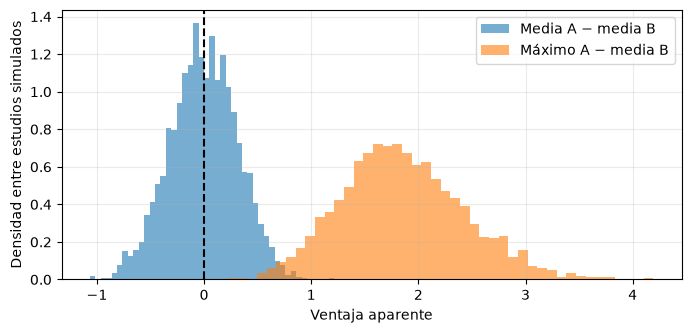

In [3]:
plt.hist(comparacion_justa, bins=45, density=True, alpha=0.6, label="Media A − media B")
plt.hist(seleccion_favorable, bins=45, density=True, alpha=0.6, label="Máximo A − media B")
plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Ventaja aparente")
plt.ylabel("Densidad entre estudios simulados")
plt.legend()
plt.show()


## 3. Cuantas más oportunidades de elegir, más fácil parece ganar

Si buscamos entre muchas semillas, crece el máximo esperado aunque ninguna configuración mejore. En una comparación real, más presupuesto de búsqueda puede mejorar una configuración de verdad; también amplía la oportunidad de seleccionar ruido. Hay que informar ese presupuesto.

La siguiente celda mantiene la misma distribución subyacente y cambia solo el número de candidatos.


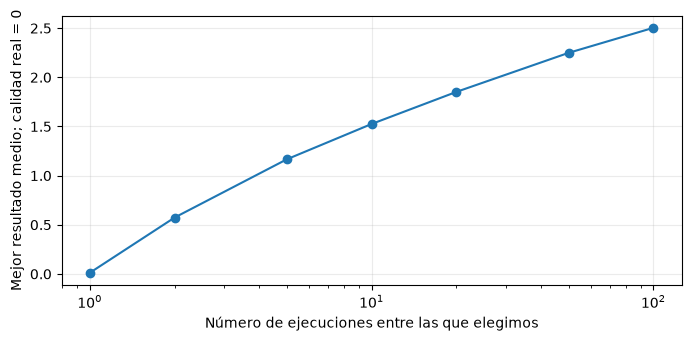

In [4]:
rng = np.random.default_rng(SEMILLA+1)
candidatos = [1, 2, 5, 10, 20, 50, 100]
ventajas = []
for cantidad in candidatos:
    datos = rng.normal(size=(5000, cantidad))
    ventajas.append(datos.max(axis=1).mean())
plt.plot(candidatos, ventajas, "o-")
plt.xscale("log")
plt.xlabel("Número de ejecuciones entre las que elegimos")
plt.ylabel("Mejor resultado medio; calidad real = 0")
plt.show()


El eje horizontal representa oportunidades de selección, no datos agregados para estimar una media. Aumentar muestras para estimar la media reduce incertidumbre; aumentar candidatos para seleccionar el máximo aumenta esta ventaja artificial. Son operaciones distintas.

## 4. Separar selección y evaluación

Supón que cada candidato tiene una calidad fija y observamos esa calidad con ruido. Seleccionamos con una medición y evaluamos con ruido independiente. En este ejemplo todas las calidades son cero, de modo que cualquier ganador sigue teniendo calidad cero.

El resultado de evaluación independiente puede ser peor que el que motivó la selección, sin que el algoritmo haya cambiado. Es regresión hacia la media después de escoger un extremo ruidoso.


Resultado usado para seleccionar: 1.8678139970633971
Resultado nuevo del candidato elegido: -0.015282368840020582


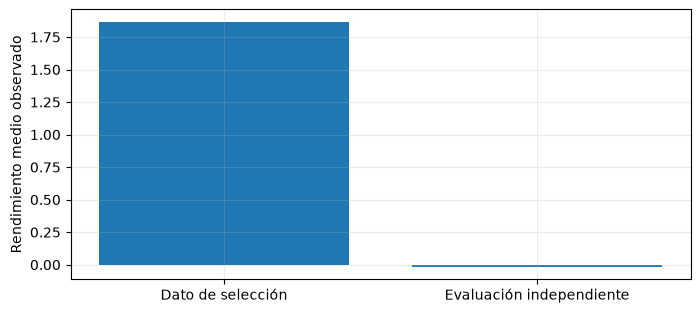

In [5]:
rng = np.random.default_rng(SEMILLA+2)
calidad_real = np.zeros((estudios, semillas))
seleccion = calidad_real + rng.normal(size=calidad_real.shape)
ganador = seleccion.argmax(axis=1)
evaluacion = calidad_real + rng.normal(size=calidad_real.shape)
filas = np.arange(estudios)
aparente = seleccion[filas, ganador]
independiente = evaluacion[filas, ganador]
print("Resultado usado para seleccionar:", aparente.mean())
print("Resultado nuevo del candidato elegido:", independiente.mean())
plt.bar(["Dato de selección", "Evaluación independiente"],
        [aparente.mean(), independiente.mean()])
plt.ylabel("Rendimiento medio observado")
plt.show()


En RL, una semilla de entrenamiento puede producir una política realmente mejor o peor. Evaluarla con nuevas semillas del entorno elimina parte del ruido de evaluación, pero no mide por sí sola la variabilidad entre entrenamientos. El diseño debe separar qué variación quiere estimar.

## 5. Un intervalo responde a una pregunta concreta

Tomamos un único estudio y calculamos la diferencia de medias. Su error estándar, para dos muestras independientes, se estima mediante

$$\mathrm{SE}=\sqrt{\frac{s_A^2}{n_A}+\frac{s_B^2}{n_B}}.$$

El intervalo normal aproximado usa $\pm1.96\,\mathrm{SE}$. Con muestras pequeñas y varianzas estimadas, una construcción con distribución t puede ser más apropiada. El bootstrap ofrece otra aproximación mediante remuestreo; tampoco es una garantía universal.

Remuestreamos A y B por separado porque en esta simulación son independientes. Si el diseño fuese pareado, habría que conservar las parejas al remuestrear.


In [6]:
a, b = A[0], B[0]
diferencia = a.mean()-b.mean()
se = np.sqrt(a.var(ddof=1)/len(a) + b.var(ddof=1)/len(b))
intervalo_normal = diferencia + np.array([-1, 1])*1.96*se

rng = np.random.default_rng(SEMILLA+3)
boot_a = a[rng.integers(0, len(a), size=(5000, len(a)))].mean(axis=1)
boot_b = b[rng.integers(0, len(b), size=(5000, len(b)))].mean(axis=1)
intervalo_boot = np.quantile(boot_a-boot_b, [0.025, 0.975])
print("Diferencia observada:", diferencia)
print("IC normal aproximado:", intervalo_normal)
print("Intervalo bootstrap percentil:", intervalo_boot)


Diferencia observada: -0.05002339599876681
IC normal aproximado: [-0.6213  0.5212]
Intervalo bootstrap percentil: [-0.603   0.4972]


Que el intervalo contenga cero no demuestra equivalencia práctica. Para estudiar equivalencia habría que definir primero qué diferencia sería relevante y diseñar la evaluación para esa pregunta. Una diferencia pequeña pero precisa también puede ser poco útil si exige muchísimo más cómputo.

## 6. ¿Qué significa «reproducible» en estos cuadernos?

La misma semilla y el mismo código permiten repetir el muestreo con la misma biblioteca y entorno. No implica que distintas versiones, hardware o algoritmos paralelos produzcan exactamente los mismos bits.

Tampoco conviene reiniciar el generador dentro de cada réplica con la misma semilla: produciríamos copias de una ejecución y aparentaríamos más evidencia de la que tenemos. Usar semillas distintas es una manera sencilla de construir réplicas separadas en estos ejemplos.


In [7]:
def muestra(seed, n=100):
    return np.random.default_rng(seed).normal(size=n)

np.testing.assert_array_equal(muestra(SEMILLA), muestra(SEMILLA))
assert not np.array_equal(muestra(SEMILLA), muestra(SEMILLA+1))
replicas_falsas = np.array([muestra(SEMILLA).mean() for _ in range(10)])
replicas_separadas = np.array([muestra(SEMILLA+k).mean() for k in range(10)])
print("Desviación entre copias de la misma réplica:", replicas_falsas.std())
print("Desviación entre semillas distintas:", replicas_separadas.std())


Desviación entre copias de la misma réplica: 0.0
Desviación entre semillas distintas: 0.05394560885315293


Las aserciones de los notebooks comprueban propiedades concretas: un objetivo terminal, una derivada o una identidad de Bellman. Que pasen no certifica por sí solo la conclusión científica de cada experimento. Para eso también importan el comparador, el presupuesto y la distribución de tareas.

## 7. Una ficha que obliga a nombrar el experimento

Antes de mostrar curvas al grupo, escribe qué has fijado y qué has variado. Una tabla de resultados sin esa información deja preguntas esenciales abiertas: ¿cambió la tarea?, ¿se usó el mismo número de interacciones?, ¿hubo búsqueda adicional de hiperparámetros?

Esta ficha es editable y se muestra en pantalla. No guarda archivos ni transmite información.


In [8]:
ficha = {
    "pregunta": "¿Añadir planificación mejora el aprovechamiento de interacciones?",
    "entorno": "Cadena determinista de nueve estados",
    "objetivo": "Llegar al terminal derecho; gamma=0.95",
    "comparador": "Dyna-Q con 0, 5 y 20 backups simulados por transición real",
    "presupuesto_datos": "El mismo número de transiciones reales por configuración",
    "presupuesto_computo": "Distinto: 1, 6 o 21 backups por transición",
    "replicas": "Varias semillas de entrenamiento, declaradas antes de comparar",
    "metrica": "Error de Q frente al óptimo y metas durante entrenamiento",
    "limite": "Modelo tabular determinista; no evalúa error de modelo neuronal",
}
for campo, valor in ficha.items():
    print(f"{campo}: {valor}")


pregunta: ¿Añadir planificación mejora el aprovechamiento de interacciones?
entorno: Cadena determinista de nueve estados
objetivo: Llegar al terminal derecho; gamma=0.95
comparador: Dyna-Q con 0, 5 y 20 backups simulados por transición real
presupuesto_datos: El mismo número de transiciones reales por configuración
presupuesto_computo: Distinto: 1, 6 o 21 backups por transición
replicas: Varias semillas de entrenamiento, declaradas antes de comparar
metrica: Error de Q frente al óptimo y metas durante entrenamiento
limite: Modelo tabular determinista; no evalúa error de modelo neuronal


La conclusión defendible sería que una configuración aprovecha mejor las interacciones en esta cadena y bajo ese presupuesto. «Planificar siempre es mejor» sería una extrapolación que el experimento no sostiene.

## 8. Ejercicio final: introducir una diferencia real

Ahora A tiene una ventaja real pequeña, pero mantenemos ruido y muestras limitadas. Compara cuánto cambia la media de todos los resultados y cuánto exagera seleccionar el mejor. Modifica la ventaja y el número de semillas.


In [9]:
VENTAJA_REAL = 0.15
SEMILLAS_POR_ESTUDIO = 30
rng = np.random.default_rng(SEMILLA+4)
a = VENTAJA_REAL + rng.normal(size=(4000, SEMILLAS_POR_ESTUDIO))
b = rng.normal(size=(4000, SEMILLAS_POR_ESTUDIO))
diferencia_medias = a.mean(axis=1)-b.mean(axis=1)
diferencia_seleccionada = a.max(axis=1)-b.mean(axis=1)
print("Ventaja real:", VENTAJA_REAL)
print("Comparación de medias:", diferencia_medias.mean())
print("Comparación seleccionada:", diferencia_seleccionada.mean())
print("Fracción de estudios cuya media favorece A:", np.mean(diferencia_medias > 0))


Ventaja real: 0.15
Comparación de medias: 0.15084014741483368
Comparación seleccionada: 2.1900546587221794
Fracción de estudios cuya media favorece A: 0.719


<details>
<summary>Solución orientativa</summary>

La comparación de medias se acerca a la ventaja real al promediar muchos estudios. La selección del mejor resultado suma una ganancia de ruido que puede superar ampliamente la mejora auténtica.

Un algoritmo realmente mejor puede perder en un estudio pequeño. Aumentar réplicas ayuda a estimar la diferencia, pero no arregla métricas equivocadas, información filtrada ni una distribución de tareas poco representativa. El diseño experimental tiene que resolver esos problemas por separado.

</details>

## 9. Recorrer el libro con una sola pregunta

En el capítulo 1 elegimos objetivo e información. En el 2 aprendimos valores; en el 3, políticas. En el 4 usamos modelos para convertir cómputo en planificación. En el 5 aparecieron otros agentes y conceptos de solución. En el 6 examinamos recompensas para respuestas y sistemas lingüísticos. En el 7 cambiaron las restricciones de exploración, representación y datos.

Para conectar todo, toma una aplicación concreta y responde: ¿qué observa el agente?, ¿qué puede hacer?, ¿quién fija la recompensa?, ¿qué datos puede conseguir?, ¿contra qué alternativa lo evaluarás? Esas decisiones suelen aclarar el algoritmo que necesitas mejor que empezar por su nombre.

Para la sesión de cierre, cada participante puede presentar una gráfica, una conclusión respaldada y una limitación. Acompáñalas con la ficha de experimento y una modificación que pondría a prueba la conclusión.

**Fuente y atribución:** [agradecimientos de Murphy](https://arxiv.org/html/2412.05265v5#Ch8), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Esta práctica metodológica es propia de la guía y se conecta con §1.3.7; no es contenido técnico atribuido al capítulo 8. [Plan del grupo](../docs/09_plan_y_glosario.md).
